# GHAgentCI 3: triggers and safeguards

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/unlv-evol/cai-miner/blob/main/notebooks/03-triggers-and-safeguards.ipynb)

How are agentic workflows wired at the latest snapshot? This notebook looks at which events start them, how often they restrict who can trigger them, what permissions they declare, how they pin the agent's action, and what tasks they appear to perform. All figures are descriptive and some fields (`actor_gated`, `tasks`) are heuristics; see the documentation.

**Dataset:** GHAgentCI, [https://doi.org/10.5281/zenodo.24088832](https://doi.org/10.5281/zenodo.24088832). **Field-by-field documentation:** [docs/DATASET.md](https://github.com/unlv-evol/cai-miner/blob/main/docs/DATASET.md).

The first code cell downloads each file from Zenodo once and caches it in a local folder (`ghagentci-data`, or the folder named by the `GHAGENTCI_DATA` environment variable).

In [1]:
import os
import urllib.request
from pathlib import Path

RECORD = "https://zenodo.org/records/24088832/files"
DATA = Path(os.environ.get("GHAGENTCI_DATA", "ghagentci-data"))


def fetch(name):
    path = DATA / name
    if not path.exists():
        DATA.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{RECORD}/{name}?download=1", path)
    return path

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# One small palette for every chart in these notebooks.
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#4a3aa7",
    "#e34948",
)
GREY = "#8a8985"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4),
        "figure.dpi": 100,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.prop_cycle": plt.cycler(
            color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]
        ),
    }
)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

In [3]:
revisions = pd.read_csv(fetch("revisions.csv.gz"), low_memory=False)
steps = pd.read_csv(fetch("steps.csv.gz"), low_memory=False)
revisions["commit_date"] = pd.to_datetime(revisions["commit_date"], utc=True)

## The latest snapshot

The last revision of each file history, without deleted files, keeping only the agentic ones.
Equal timestamps are broken by row order (the tables list each history newest first).

In [4]:
REV = ["repository", "uid", "commit_hash"]
revisions["position"] = np.arange(len(revisions))
latest = (
    revisions.sort_values(["commit_date", "position"], ascending=[True, False])
    .groupby(["repository", "uid"])
    .tail(1)
)
latest = latest[(latest["git_change_type"] != "Deleted") & latest["agentic"]].copy()
snap_steps = steps.merge(latest[REV], on=REV)
print(
    f"{len(latest):,} agentic workflows in {latest['repository'].nunique():,} repositories, "
    f"with {len(snap_steps):,} invocations"
)

9,265 agentic workflows in 4,598 repositories, with 12,939 invocations


## Triggers

`triggers` lists the events in the workflow's `on:` block. A workflow usually has several, so the
shares add up to more than 100%. `roles` is not a GitHub event: it is a gh-aw frontmatter key
(who may trigger the workflow) that sits under `on:` in gh-aw sources.

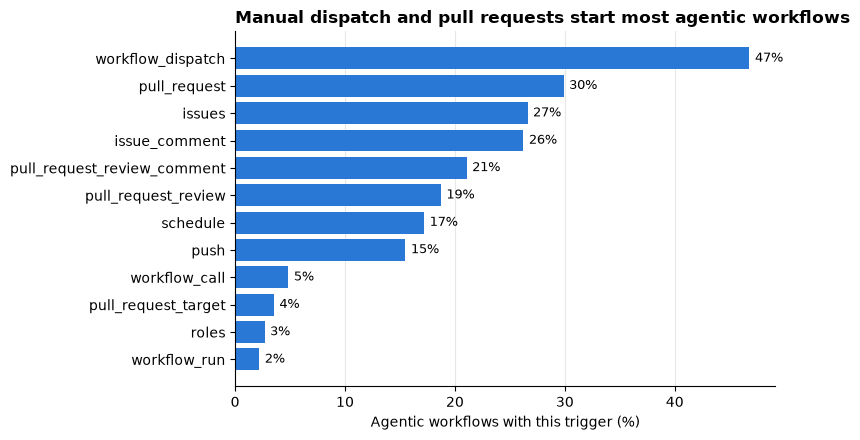

In [5]:
trig = (
    latest[["repository", "uid", "triggers"]]
    .assign(trigger=latest["triggers"].str.split("|"))
    .explode("trigger")
    .dropna(subset=["trigger"])
)
trig_share = trig.groupby("trigger")["uid"].size().div(len(latest)).sort_values(ascending=False)

top = trig_share.head(12).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, 100 * top.values, color=BLUE)
for y, v in enumerate(top.values):
    ax.text(100 * v + 0.5, y, f"{v:.0%}", va="center", fontsize=9)
ax.set_xlabel("Agentic workflows with this trigger (%)")
ax.set_title("Manual dispatch and pull requests start most agentic workflows")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## Actor gating

`actor_gated` is a **loose heuristic**. The documentation describes it as an `if:` condition on
the triggering actor or their association, but the miner sets it when the workflow text anywhere
contains one of `github.actor`, `github.triggering_actor`, `github.event.sender`, `association`,
`github.event.comment.body` or `contains(github.event`. The last two also match the usual
`contains(github.event.comment.body, '@claude')` mention check, which filters on *what* a comment
says rather than *who* wrote it. Read the share below as an upper bound on workflows that restrict
who can start them; it is nearly 100% for comment-triggered workflows mostly for that reason.
Checking real restrictions requires reading the workflow content (notebook 4).

In [6]:
print(f"actor-gated agentic workflows: {latest['actor_gated'].eq(True).mean():.1%}")
gated = trig.merge(latest[["repository", "uid", "actor_gated"]], on=["repository", "uid"])
events = [
    "issue_comment",
    "pull_request_review_comment",
    "issues",
    "pull_request_target",
    "pull_request",
    "workflow_dispatch",
    "schedule",
    "push",
]
(
    gated[gated["trigger"].isin(events)]
    .groupby("trigger")["actor_gated"]
    .agg(workflows="size", gated=lambda s: s.eq(True).mean())
    .loc[events]
    .style.format({"gated": "{:.1%}", "workflows": "{:,}"})
)

actor-gated agentic workflows: 48.5%


,workflows,gated
trigger,,
issue_comment,"2,430",97.2%
pull_request_review_comment,"1,952",98.0%
issues,"2,465",82.8%
pull_request_target,327,54.7%
pull_request,"2,769",39.3%
workflow_dispatch,"4,336",28.4%
schedule,"1,594",33.3%
push,"1,436",8.2%


## Declared permissions

`permissions` is the workflow-level `permissions:` block, flattened to `scope level` pairs
(for example `contents read pull-requests write`), or a single `read-all`/`write-all`. Without a
block the job's token gets the repository's default permissions. Job-level blocks are not included,
so "no workflow-level block" does not mean "unrestricted".

no workflow-level permissions block: 67.2%
read-all: 1.5%   write-all: 0.0%


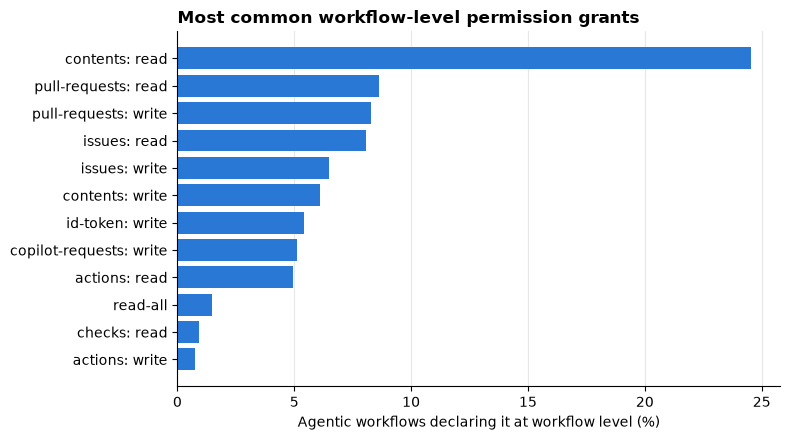

In [7]:
perm = latest["permissions"]
print(f"no workflow-level permissions block: {perm.isna().mean():.1%}")
print(f"read-all: {perm.eq('read-all').mean():.1%}   write-all: {perm.eq('write-all').mean():.1%}")


def pairs(text):
    tokens = text.split()
    return tokens if len(tokens) == 1 else [f"{a}: {b}" for a, b in zip(tokens[::2], tokens[1::2])]


declared = perm.dropna().map(pairs).explode()
pair_share = declared.value_counts().div(len(latest)).head(12).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(pair_share.index, 100 * pair_share.values, color=BLUE)
ax.set_xlabel("Agentic workflows declaring it at workflow level (%)")
ax.set_title("Most common workflow-level permission grants")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## How agent actions are referenced

For invocations through a Marketplace action (`evidence_kind == "uses"`), `action_version` is the
reference after `@`. A full 40-character commit SHA is immutable; a tag (`v1`, `v1.0.3`) or a
branch (`main`, `beta`) can be moved by the action's owner. Below, anything that is neither a SHA
nor version-like is counted as a branch or other name.

most common non-SHA, non-tag references: {'beta': 400, 'main': 52, 'latest': 5, 'eap': 3, '<commit-sha-pinned-after-enable>': 1}


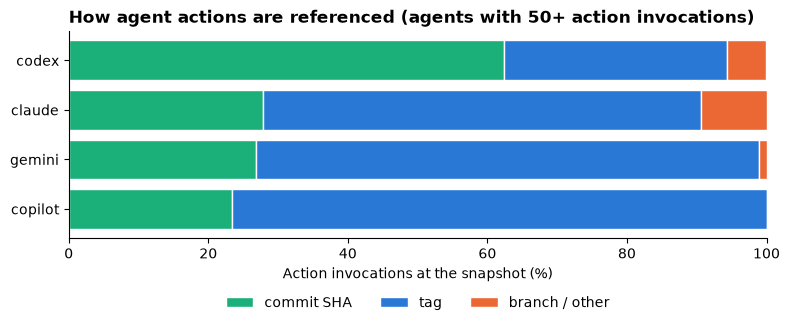

reference,commit SHA,tag,branch / other,total
agent,,,,
claude,1233,2786,419,4438
codex,131,67,12,210
copilot,36,118,0,154
gemini,50,134,2,186


In [8]:
uses = snap_steps[
    (snap_steps["evidence_kind"] == "uses") & snap_steps["action_version"].notna()
].copy()
uses["reference"] = np.select(
    [
        uses["action_version"].str.fullmatch(r"[0-9a-f]{40}"),
        uses["action_version"].str.match(r"v?\d"),
    ],
    ["commit SHA", "tag"],
    default="branch / other",
)
print(
    "most common non-SHA, non-tag references:",
    uses.loc[uses["reference"] == "branch / other", "action_version"]
    .value_counts()
    .head(5)
    .to_dict(),
)

kinds = ["commit SHA", "tag", "branch / other"]
by_agent = pd.crosstab(uses["agent"], uses["reference"])[kinds]
by_agent = by_agent[by_agent.sum(axis=1) >= 50]
share = by_agent.div(by_agent.sum(axis=1), axis=0).sort_values("commit SHA")

fig, ax = plt.subplots(figsize=(8, 3.5))
left = np.zeros(len(share))
for kind, color in zip(kinds, [AQUA, BLUE, ORANGE]):
    ax.barh(
        share.index,
        100 * share[kind],
        left=left,
        color=color,
        label=kind,
        edgecolor="white",
        linewidth=1,
    )
    left += 100 * share[kind].values
ax.set_xlim(0, 100)
ax.set_xlabel("Action invocations at the snapshot (%)")
ax.set_title("How agent actions are referenced (agents with 50+ action invocations)")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22))
ax.grid(visible=False)
plt.tight_layout()
plt.show()
by_agent.assign(total=by_agent.sum(axis=1))

## Task labels

`tasks` labels each invocation with heuristic purposes inferred from triggers and names (`review`,
`triage`, `implement`, `test`, `docs`, `security`, `scheduled`, `on_demand`). A workflow carries a
label if any of its invocations does; workflows can carry several.

workflows with no label: 5.4%


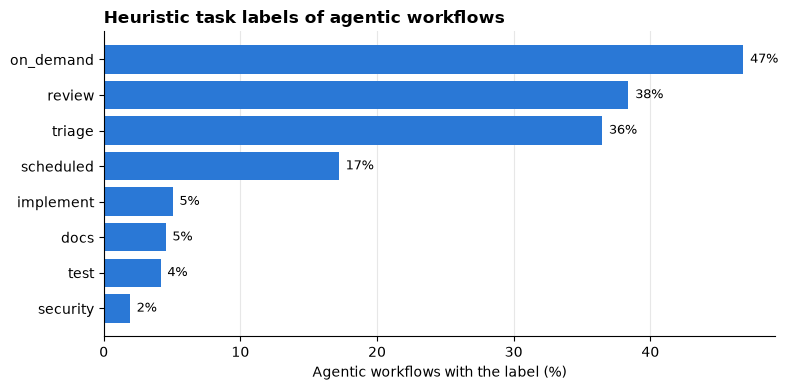

In [9]:
labels = (
    snap_steps[["repository", "uid", "tasks"]]
    .dropna()
    .assign(task=lambda d: d["tasks"].str.split("|"))
    .explode("task")
    .drop_duplicates(["repository", "uid", "task"])
)
task_share = labels["task"].value_counts().div(len(latest)).sort_values()
print(
    f"workflows with no label: {1 - latest.set_index(['repository', 'uid']).index.isin(labels.set_index(['repository', 'uid']).index).mean():.1%}"
)

fig, ax = plt.subplots()
ax.barh(task_share.index, 100 * task_share.values, color=BLUE)
for y, v in enumerate(task_share.values):
    ax.text(100 * v + 0.5, y, f"{v:.0%}", va="center", fontsize=9)
ax.set_xlabel("Agentic workflows with the label (%)")
ax.set_title("Heuristic task labels of agentic workflows")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Next: [04-gh-aw-and-workflow-content](04-gh-aw-and-workflow-content.ipynb) looks at GitHub
Agentic Workflows and at the workflow files themselves.